# Validate snow cover fraction on CDSE

Runs the SCF pipeline (S2 L1C -> inputs cube -> representative pixels UDF -> SVM) for one experiment config.
Optionally also downloads the inputs cube (bands, indices, `shadow_mask`, `local_solar_incidence_angle`) for debugging.

Output: SCF 0-100, 255 = nodata/invalid.

In [ ]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "scripts" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import openeo
import shapely
import xarray as xr
import matplotlib.pyplot as plt
from omegaconf import OmegaConf
from pyproj import Transformer
from shapely.ops import transform

from openeo_mountains_snow.snow_cover_fraction.snow_cover_fraction import (
    aoi_neighborhood_size, snow_cover_fraction_cube, snowflake_inputs_cube)

EXPERIMENT = "aguirre_small"   # file in src/openeo_mountains_snow/conf/experiment/
OUT = ROOT / "tmp" / f"validate_{EXPERIMENT}"
OUT.mkdir(parents=True, exist_ok=True)

conf = ROOT / "src/openeo_mountains_snow/conf"
cfg = OmegaConf.merge(OmegaConf.load(conf / "config.yaml"),
                      {"experiment": OmegaConf.load(conf / "experiment" / f"{EXPERIMENT}.yaml")})
aoi = shapely.box(*cfg.experiment.aoi)
if cfg.experiment.aoi_crs is not None:
    aoi = transform(Transformer.from_crs(cfg.experiment.aoi_crs, "EPSG:4326", always_xy=True).transform, aoi)
time_period = list(cfg.experiment.temporal_extent)
print(aoi.bounds, time_period, "neighborhood px:", aoi_neighborhood_size(aoi))


(-70.62001240310295, -36.00872064125644, -70.5298817400199, -35.935455666494406) ['2015-08-18', '2015-08-19']


C:\Users\VROMPAYH\AppData\Local\Temp\ipykernel_21972\475814122.py:29: DeprecationWarning: The 'shapely.ops.transform()' function is deprecated. Use 'shapely.transform()' or 'shapely.transform_coordseq()' instead. See https://shapely.readthedocs.io/en/latest/manual.html#shapely.ops.transform for more details.
  aoi = transform(Transformer.from_crs(cfg.experiment.aoi_crs, "EPSG:4326", always_xy=True).transform, aoi)


In [2]:
c = openeo.connect(cfg.connection.endpoint).authenticate_oidc()

Authenticated using refresh token.


## SCF job

In [ ]:
scf = snow_cover_fraction_cube(aoi, time_period, c, cfg)
scf_job = scf.create_job(out_format="netCDF", title=f"{cfg.experiment.title_prefix} SCF",
                         job_options=dict(cfg.experiment.job_options))
scf_job.start_and_wait()


0:00:00 Job 'j-261113145158400b982eb3731a78607f': send 'start'
0:00:02 Job 'j-261113145158400b982eb3731a78607f': created (progress 0%)
0:00:07 Job 'j-261113145158400b982eb3731a78607f': queued (progress 0%)
0:00:14 Job 'j-261113145158400b982eb3731a78607f': queued (progress 0%)
0:00:22 Job 'j-261113145158400b982eb3731a78607f': queued (progress 0%)
0:00:32 Job 'j-261113145158400b982eb3731a78607f': queued (progress 0%)
0:00:44 Job 'j-261113145158400b982eb3731a78607f': running (progress N/A)
0:00:59 Job 'j-261113145158400b982eb3731a78607f': running (progress N/A)
0:01:19 Job 'j-261113145158400b982eb3731a78607f': running (progress N/A)
0:01:43 Job 'j-261113145158400b982eb3731a78607f': running (progress N/A)
0:02:13 Job 'j-261113145158400b982eb3731a78607f': running (progress N/A)
0:02:50 Job 'j-261113145158400b982eb3731a78607f': running (progress N/A)
0:03:37 Job 'j-261113145158400b982eb3731a78607f': running (progress N/A)
0:04:35 Job 'j-261113145158400b982eb3731a78607f': running (progress N/

<BatchJob job_id='j-261113145158400b982eb3731a78607f'>

In [4]:


def report(job):
    d = job.describe()
    print(job.job_id, d.get("status"), "costs:", d.get("costs"), "usage:", d.get("usage"))
    for log in job.logs():
        msg = str(log.get("message", ""))
        if log.get("level") in ("error", "warning") or "classification" in msg:
            print(log.get("level"), msg[:500])

# Connect and reattach to a previous successful job (skip the SCF job cell above)
c = openeo.connect(cfg.connection.endpoint).authenticate_oidc()
scf_job = c.job("j-261113145158400b982eb3731a78607f")
report(scf_job)


Authenticated using refresh token.
j-261113145158400b982eb3731a78607f finished costs: 47 usage: {'cpu': {'unit': 'cpu-seconds', 'value': 27269.999999999996}, 'cpu_utilization_ratio': {'unit': 'fraction', 'value': 0.3753069189741639}, 'duration': {'unit': 'seconds', 'value': 2445}, 'input_pixel': {'unit': 'mega-pixel', 'value': 12.629493713378906}, 'max_executor_memory': {'unit': 'gb', 'value': 3.910205841064453}, 'memory': {'unit': 'mb-seconds', 'value': 109348079.99999999}, 'memory_requested': {'unit': 'mb-seconds', 'value': 114249840}, 'network_received': {'unit': 'b', 'value': 2017058281}, 'total_stage_failures': {'unit': 'count', 'value': 0}}
warning Merging dependencies from multiple UDF runtimes/versions
error pip output:44 ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
warning Deriving band listing from unordered `item_assets`
warning Deriving band list

nodata (255) fraction: 0.001194550740592181


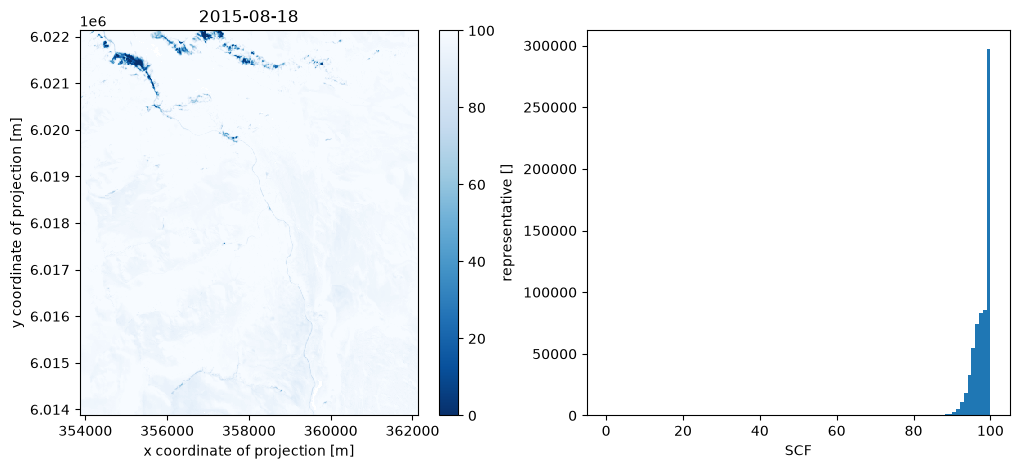

In [5]:
nc = OUT / "scf_bigpx" / "openEO.nc"
if not nc.exists() or nc.stat().st_size == 0:
    scf_job.get_results().download_files(OUT / "scf_bigpx")
with xr.open_dataset(nc) as ds:
    scf_da = ds["representative"].load()
scf_da

vals, counts = np.unique(scf_da.values, return_counts=True)
print("nodata (255) fraction:", counts[vals == 255].sum() / counts.sum())

for t in scf_da.t.values:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
    img = scf_da.sel(t=t).where(scf_da.sel(t=t) != 255)
    img.plot(ax=ax1, vmin=0, vmax=100, cmap="Blues_r")
    ax1.set_title(str(t)[:10])
    ax2.hist(img.values[np.isfinite(img.values)], bins=101)
    ax2.set_xlabel("SCF")
    plt.show()


## Optional: inputs cube (debugging)
Downloads what the UDF receives: reflectance bands, NDSI/NDWI/diff_B_NIR, `shadow_mask`, `local_solar_incidence_angle`.

In [ ]:
inputs = snowflake_inputs_cube(aoi, time_period, c, cfg)
inputs_job = inputs.create_job(out_format="netCDF", title=f"{cfg.experiment.title_prefix} inputs",
                               job_options=dict(cfg.experiment.job_options))
inputs_job.start_and_wait()
report(inputs_job)
files = inputs_job.get_results().download_files(OUT / "inputs")
inp = xr.open_dataset(next(f for f in files if f.suffix == ".nc"))
print(inp.data_vars)

In [ ]:
t0 = inp.t.values[0]
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, band, kw in zip(axes, ["B03", "NDSI", "shadow_mask", "local_solar_incidence_angle"],
                        [dict(vmin=0, vmax=1), dict(vmin=-1, vmax=1), {}, dict(vmin=0, vmax=180)]):
    inp[band].sel(t=t0).plot(ax=ax, **kw)
    ax.set_title(band)
plt.show()